# Extended Analysis: Constraining Parameter Space for Homeostatic Plasticity

This notebook extends the analysis from TMR_1.ipynb to incorporate additional mathematical and biological constraints:

1. **Load optimized parameters** (theta_opt)
2. **Stability analysis** - Verify all solutions are stable
3. **Participation ratio analysis** - Histogram and filtering
4. **Extended constraints:**
   - PPR-based filtering
   - Exclusion of silencing/saturating eigen-directions
   - Excitatory-inhibitory balance
   - Biologically plausible Naka-Rushton parameters
   - Consistency with dopaminergic axon shrinkage
5. **Validation** - Check if participation ratio is a good metric for finding zero eigenvalues

In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from scipy import stats

# Set random seed for reproducibility
key = jax.random.PRNGKey(42)
np.random.seed(42)

# Plotting style
plt.rcParams.update({'font.size': 12, 'figure.figsize': (10, 6)})

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal


In [2]:
# Naka-Rushton function
def nr(x, n=4):
    """Naka-Rushton activation function"""
    return x**n / (x**n + 1)

# Unpack parameters
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    w_r_g = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    W_g_y = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y

# Fixed-point function for green neurons
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
    """Fixed point equation for green neurons"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input)
    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input)
    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input)
    return g_new

# Solve fixed point via Anderson Acceleration
def solve_fixed_point(theta, x, m):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)
    aa = AndersonAcceleration(mitral_fixed_point, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output
def mitral_output(theta, x, m):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g = solve_fixed_point(theta, x, m)
    b = nr(w_osn_b * alpha * x)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r)
    return r, g, b, y


## 1. Load Optimised Parameters

In [39]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_1000_samples_n_4_target_0.5.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")


Loaded theta_opt with shape: (1000, 28)
Number of samples: 1000
Number of parameters per sample: 28


## 2. Parameter Changes Preserving Output ($\Delta \theta$)

Processing 1000 samples...
  Sample 1/1000...
  Sample 101/1000...
  Sample 201/1000...
  Sample 301/1000...
  Sample 401/1000...
  Sample 501/1000...
  Sample 601/1000...
  Sample 701/1000...
  Sample 801/1000...
  Sample 901/1000...
Completed processing 1000 samples


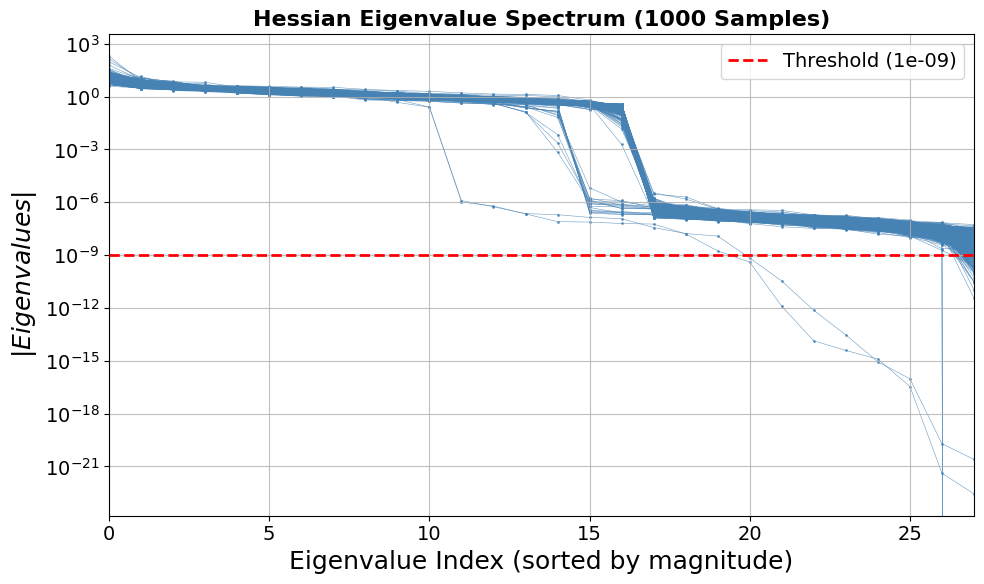

In [59]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-9

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(10, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (light, transparent)
ax.semilogy(all_eigenvalues.T, 'o-', ms=1, lw=0.4, alpha=0.8, color='steelblue', zorder=1)

# Plot statistics
ax.axhline(near_zero_threshold, color='r', ls='--', lw=2, label=f'Threshold ({near_zero_threshold})', zorder=5)

ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=18)
ax.set_ylabel('$|Eigenvalues|$', fontsize=18)
ax.set_xlim(0, n_params-1)
ax.tick_params(axis='both', labelsize=14, direction='out')
ax.legend(fontsize=14)
ax.grid(True, alpha=0.8)
ax.set_title(f'Hessian Eigenvalue Spectrum ({n_samples} Samples)', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()


In [ ]:
selected_eigenvalues = all_eigenvalues[(all_eigenvalues < 1e-9).any(axis=1)]
selected_eigenvectors = all_eigenvectors[(all_eigenvalues < 1e-9).any(axis=1)]

# Get the indices of selected samples
selected_indices = np.where((all_eigenvalues < 1e-9).any(axis=1))[0]
print(selected_eigenvalues.shape[0], "out of", all_eigenvalues.shape[0])

74 out of 1000


In [80]:
dot_products = np.zeros((selected_eigenvectors.shape[0], selected_eigenvectors.shape[2]))
for i in range(selected_indices.shape[0]):
    original_sample_idx = selected_indices[i]  # Get the original sample index

    grad_vec = np.array(grad(theta_samples[original_sample_idx]))
    # Normalise gradient vector
    grad_vec = grad_vec / np.linalg.norm(grad_vec)

    # Normalise eigenvectors (each column is an eigenvector)
    eigenvectors_i = selected_eigenvectors[i]  # Shape: (28, 28)
    # Normalise each column (eigenvector) to unit length
    norms = np.linalg.norm(eigenvectors_i, axis=0, keepdims=True)
    normalised_eigenvectors = eigenvectors_i / norms

    # Compute dot product of each normalized eigenvector (column) with normalized gradient
    dot_products[i] = normalised_eigenvectors.T @ grad_vec

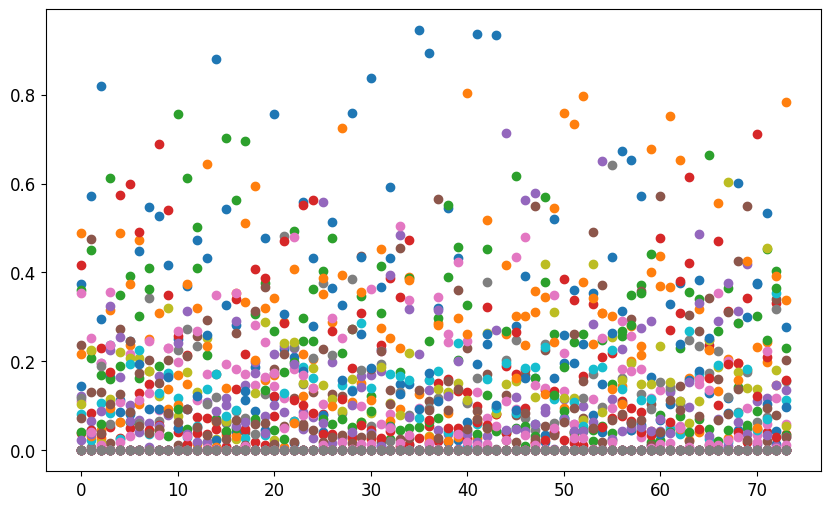

In [85]:
#plot dot_products
plt.plot(np.abs(dot_products),"o")
plt.show()

In [92]:
mask = np.abs(dot_products) > 0.1
print(mask)

[[ True  True  True ... False False False]
 [ True  True  True ... False False False]
 [ True False  True ... False False False]
 ...
 [ True  True  True ... False False False]
 [False  True  True ... False False False]
 [ True  True  True ... False False False]]


In [ ]:
perpendicular_threshold = 0.01

selected_perpendicular_eigenvalues = selected_eigenvalues.copy()
mask = np.abs(dot_products) > perpendicular_threshold  # shape: (n_selected, eig_dim)
selected_perpendicular_eigenvalues[mask] = 10000
